# Cross-task social-context decoding

**A NeurodeskEDU teaching draft using 67 public participants and 804 outcome maps.**

Can a classifier trained to distinguish human from computer context in Shared Reward do the same in Trust, for people it has never seen? We will build the condition maps, keep participants separated during training and testing, and inspect predictions and brain patterns.

**Before you start:** open this notebook in **Neurodesk Play** and use its default **Python [conda env:base]** kernel. Choose **Kernel → Restart Kernel and Run All Cells**, or use **Shift+Enter** to work through one cell at a time. There is no package installation, environment creation, setup script or custom kernel registration. The notebook is self-contained; you do not need a separate configuration file.

The first code cell loads **FSL 6.0.7.22**. Its included Python provides scikit-learn for the classifier. Cells beginning `%%script fslpython` run the visible Python code inside that module; other Python cells use the default notebook kernel. Files in `outputs/` carry results between them. This keeps the versioned tool environment intact without installing anything.

Allow roughly **1.5 GB of disk space**. The first run downloads about **310 MB** of public maps and 1.5 MB of independent template references. Later runs reuse verified downloads. Loading an uncached Neurodesk module can also take time.

**Prepared for:** David V. Smith; Jacob and Riccardo will review the teaching content and independently reproduce it. Final authorship will reflect actual contributions. **Updated:** October 28, 2026.

**Licenses:** code MIT; original explanations CC BY 4.0; the separate map archive CC0. External templates and software retain their upstream terms. Codex assisted with drafting code and explanations; human scientific and teaching review remains before submission.

## What you will learn

1. Read a signed fMRI effect estimate, called a COPE.
2. Average outcome conditions into human and computer patterns.
3. Keep each participant out of training when predicting that person's maps in either task.
4. Read paired ordering accuracy, bootstrap intervals and permutation tests.
5. Distinguish decoder coefficients from forward patterns.

**Data boundary:** the original source is [OpenNeuro ds005123 v1.0.0](https://doi.org/10.18112/openneuro.ds005123.v1.0.0), N=114. This teaching release contains 67 people after existing QC, complete-input checks and exclusion of participants protected for the parent paper's independent validation. Exclusions happened before export. Public availability does not make a reserved participant eligible for model development. The folds below are temporary splits inside this permitted teaching subset.

We use only the fixed [Zenodo teaching release](https://doi.org/10.5281/zenodo.23718599). This notebook never needs private participant lists, paper models or reserved images.

## 1. Load the versioned Neurodesk module

`module.load` is the notebook equivalent of the terminal command `ml fsl/6.0.7.22`. The version is explicit so that another learner can load the same tools. We use FSL to inspect a map and use its bundled Python for model fitting. Loading a module makes its tools available; it does not install packages into the notebook kernel.

In [1]:
import module

await module.load("fsl/6.0.7.22")
await module.list()

['fsl/6.0.7.22']

Import the libraries already supplied by Neurodesk Play. `Path` works with filenames; NumPy works with arrays; pandas works with tables; NiBabel reads NIfTI images; Matplotlib draws figures. The choices below stay fixed throughout the example.

In [2]:
from pathlib import Path
import hashlib
import itertools
import json
import os
import platform
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import nibabel as nib
from nibabel.processing import resample_from_to
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 20261027
N_FOLDS = 5
N_PERMUTATIONS = 999
C = 1.0
TASKS = ["sharedreward", "trust"]
PARTNERS = ["computer", "friend", "stranger"]
VALENCES = ["positive", "negative"]

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs") / "public"
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()
settings = {"seed": SEED, "folds": N_FOLDS, "C": C, "permutations": N_PERMUTATIONS}
(OUTPUT_DIR / "settings.json").write_text(json.dumps(settings, indent=2));

Check the Python supplied by the module. The first line below is a Jupyter **cell magic**: everything below it runs with `fslpython`. No Python function or hidden helper script is called. The fitting cells below limit numerical libraries to one CPU thread, which keeps resource use modest on Play.

In [3]:
%%script fslpython
import importlib.metadata
import json
import os
from pathlib import Path
import sys

packages = ["numpy", "scipy", "scikit-learn", "threadpoolctl"]
versions = {}
for package in packages:
    versions[package] = importlib.metadata.version(package)

runtime = {"python": sys.version.split()[0], "packages": versions}
Path("outputs/public/fsl_python_environment.json").write_text(json.dumps(runtime, indent=2))
print("FSL module's Python:", runtime)

FSL module's Python: {'python': '3.12.13', 'packages': {'numpy': '2.1.3', 'scipy': '1.17.1', 'scikit-learn': '1.5.2', 'threadpoolctl': '3.6.0'}}


## 2. Download the teaching maps and independent references

A **checksum** is a fingerprint of a file's bytes. We pin both the file URL and its SHA256 checksum. A changed or incomplete download stops the notebook instead of silently using different data.

The three files below are the public map archive, an independent brain mask and an anatomical image for plotting. TemplateFlow references are downloaded from their provider; they are not part of the CC0 archive. No participant image is used to choose which brain voxels enter the analysis.

In [4]:
archive_sha = "08ea0ccfa3df67ec9ec34b29a50d852d5c0e53e5c1ad654073587c37dddd10ae"
mask_sha = "e4e2b284170271afdafe26ac0997b2af5a0f5ddac35e28a7e796b52e8bc5adb1"
anatomy_sha = "2a814da50173599a857d96246dc057d548072bd6dffa499f75724dbad20792b1"

resources = [
    {"name": "Teaching maps", "path": DATA_DIR / (archive_sha + ".zip"),
     "url": "https://zenodo.org/api/records/23718599/files/public_outcome_copes_v1.0.0.zip/content",
     "sha256": archive_sha},
    {"name": "Independent mask", "path": DATA_DIR / ("template-" + mask_sha + ".nii.gz"),
     "url": "https://templateflow.s3.amazonaws.com/tpl-MNI152NLin6Asym/tpl-MNI152NLin6Asym_res-02_desc-brain_mask.nii.gz",
     "sha256": mask_sha},
    {"name": "Anatomical reference", "path": DATA_DIR / ("anatomy-" + anatomy_sha + ".nii.gz"),
     "url": "https://templateflow.s3.amazonaws.com/tpl-MNI152NLin6Asym/tpl-MNI152NLin6Asym_res-02_T1w.nii.gz",
     "sha256": anatomy_sha},
]

In [5]:
# Download and verify each file before opening it.
for resource in resources:
    path = resource["path"]
    if not path.exists():
        print("Downloading:", resource["name"])
        temporary_path = path.with_suffix(".part")
        urllib.request.urlretrieve(resource["url"], temporary_path)
        with temporary_path.open("rb") as stream:
            checksum = hashlib.file_digest(stream, "sha256").hexdigest()
        assert checksum == resource["sha256"], "Download checksum mismatch: " + resource["name"]
        temporary_path.replace(path)
    with path.open("rb") as stream:
        checksum = hashlib.file_digest(stream, "sha256").hexdigest()
    assert checksum == resource["sha256"], "Cached file changed: " + resource["name"]
    print("Verified:", resource["name"])

RELEASE_DIR = DATA_DIR / ("public-" + archive_sha[:16])
with zipfile.ZipFile(resources[0]["path"]) as archive:
    # Check the paths before extracting the checksum-verified archive.
    for name in archive.namelist():
        assert not Path(name).is_absolute() and ".." not in Path(name).parts
    archive.extractall(RELEASE_DIR)
print("Maps are in:", RELEASE_DIR)

Verified: Teaching maps
Verified: Independent mask
Verified: Anatomical reference
Maps are in: data/public-08ea0ccfa3df67ec


## 3. Read the manifest and check the images

The manifest has one row per map. It tells us the participant, task, partner, outcome valence, original contrast name and file location. Each participant must contribute all 12 conditions: **2 tasks × 3 partners × 2 valences**. These checks verify the released files; they do not reselect participants or recreate the private export audit.

In [6]:
manifest = pd.read_csv(RELEASE_DIR / "manifest.csv")
subjects = sorted(manifest.participant_id.unique())

assert len(subjects) == 67 and len(manifest) == 804
assert manifest.source_dataset.eq("ds005123").all()
assert manifest.source_version.eq("1.0.0").all()
assert manifest.phase.eq("outcome").all() and manifest.qc_included.eq(True).all()
assert not manifest.duplicated(["participant_id", "task", "partner", "valence"]).any()

expected_conditions = set(itertools.product(TASKS, PARTNERS, VALENCES))
for person, rows in manifest.groupby("participant_id"):
    conditions = set(zip(rows.task, rows.partner, rows.valence))
    assert conditions == expected_conditions, "Missing conditions for " + person

for row in manifest.itertuples():
    path = (RELEASE_DIR / row.path).resolve()
    assert path.is_relative_to(RELEASE_DIR.resolve()) and path.is_file()
    with path.open("rb") as stream:
        checksum = hashlib.file_digest(stream, "sha256").hexdigest()
    assert checksum == row.sha256, "Map checksum mismatch: " + row.path

print(len(subjects), "participants;", len(manifest), "verified maps")
display(manifest[["task", "partner", "valence", "contrast_name"]].drop_duplicates().reset_index(drop=True))

67 participants; 804 verified maps


,task,partner,valence,contrast_name
0,sharedreward,computer,negative,C_pun
1,sharedreward,computer,positive,C_rew
2,sharedreward,friend,negative,F_pun
3,sharedreward,friend,positive,F_rew
4,sharedreward,stranger,negative,S_pun
5,sharedreward,stranger,positive,S_rew
6,trust,computer,negative,C_def
7,trust,computer,positive,C_rec
8,trust,friend,negative,F_def
9,trust,friend,positive,F_rec


Inspect one permitted map with the loaded FSL tools. `fslinfo` prints its image dimensions and voxel sizes. `fslstats -R` prints its minimum and maximum values. A COPE is a **signed effect estimate**, not a z-statistic: negative values are valid and must be retained.

In [7]:
example_path = RELEASE_DIR / manifest.iloc[0].path
!fslinfo {example_path}
!fslstats {example_path} -R

data_type	FLOAT32
dim1		57
dim2		70
dim3		54
dim4		1
datatype	16
pixdim1		2.700000
pixdim2		2.700000
pixdim3		2.970000
pixdim4		1.615000
cal_max		1206.606201
cal_min		-3132.789551
file_type	NIFTI-1+
-3132.789551 1206.606201 


### Put the independent mask on the maps' grid

The template mask and COPEs use the same MNI coordinate system but have different voxel grids. We resample the binary mask with **nearest-neighbor interpolation** to the common COPE grid, then verify its expected voxel fingerprint. This is an independently defined mask, not a mask selected by classifier performance. The resampling reference supplies grid geometry only.

In [8]:
reference = nib.load(example_path)
metadata = json.loads((RELEASE_DIR / "dataset_description.json").read_text())
assert metadata["MaskDistribution"] == "external_reference_only"

template_mask = nib.load(resources[1]["path"])
resampled_mask = resample_from_to(template_mask, (reference.shape, reference.affine), order=0)
mask_values = resampled_mask.get_fdata().astype("uint8")
expected_mask_sha = metadata["MaskProvenance"]["expected_resampled_mask_data_sha256"]
assert hashlib.sha256(mask_values.tobytes(order="C")).hexdigest() == expected_mask_sha
mask = mask_values.astype(bool)
assert mask.sum() == 84479

anatomy = resample_from_to(nib.load(resources[2]["path"]), (reference.shape, reference.affine), order=1)
print("Common grid:", reference.shape, "| voxel sizes:", reference.header.get_zooms())
print("Independent mask:", mask.sum(), "voxels")

Common grid: (57, 70, 54) | voxel sizes: (np.float32(2.7), np.float32(2.7), np.float32(2.97))
Independent mask: 84479 voxels


## 4. Build one human/computer pair per participant and task

First, average the two outcome valences within each partner. Then average friend and stranger equally to make the **human** class. The **computer** class uses the computer valence average.

| Task | Human map | Computer map |
| --- | --- | --- |
| Shared Reward | mean of friend/stranger × reward/punishment | mean of computer reward/punishment |
| Trust | mean of friend/stranger × reciprocation/defection | mean of computer reciprocation/defection |

`X` is a four-dimensional array: **participant × task × class × voxel**. Class 0 is human; class 1 is computer. We subtract each map's own spatial mean so an overall map level alone cannot drive the classifier. This does not remove every generic task effect.

In [9]:
lookup = manifest.set_index(["participant_id", "task", "partner", "valence"])
X = np.empty((len(subjects), 2, 2, int(mask.sum())), dtype="float32")

for person_index, person in enumerate(subjects):
    for task_index, task in enumerate(TASKS):
        partner_maps = {}
        for partner in PARTNERS:
            outcome_maps = []
            for valence in VALENCES:
                row = lookup.loc[(person, task, partner, valence)]
                image = nib.load(RELEASE_DIR / row.path)
                assert image.shape == reference.shape
                assert np.allclose(image.affine, reference.affine, atol=1e-5, rtol=0)
                values = image.get_fdata(dtype=np.float32)
                assert np.isfinite(values).all()
                outcome_maps.append(values[mask])
            partner_maps[partner] = np.mean(outcome_maps, axis=0)

        human_map = (partner_maps["friend"] + partner_maps["stranger"]) / 2
        computer_map = partner_maps["computer"]
        X[person_index, task_index, 0] = human_map
        X[person_index, task_index, 1] = computer_map

X -= X.mean(axis=-1, keepdims=True)
np.save(OUTPUT_DIR / "features.npy", X)
print("participant × task × class × voxel:", X.shape)
print("Saved features for the module's Python:", OUTPUT_DIR / "features.npy")

participant × task × class × voxel: (67, 2, 2, 84479)
Saved features for the module's Python: outputs/public/features.npy


## 5. Train on Shared Reward and predict two tasks

A linear support-vector classifier learns one weight per voxel. Positive labels mean human; negative labels mean computer. We keep its settings fixed, rather than trying alternatives and choosing the best accuracy.

We divide the 67 people into five **folds**. For each fold, train on the other four folds' Shared Reward maps. Predict both Shared Reward and Trust maps for the excluded people. No map from a test participant enters that fold's training.

The cell below runs in FSL's Python because that environment supplies scikit-learn. It reads the feature array saved above and saves the results for later plots. `reshape` places each participant's human and computer maps on separate training rows. The human-minus-computer **margin** is positive when the human map receives the higher score.

In [10]:
%%script fslpython
from pathlib import Path
import json
import warnings
import numpy as np
from sklearn.model_selection import KFold
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

warnings.simplefilter("error", ConvergenceWarning)
thread_limit = threadpool_limits(limits=1)
out = Path("outputs/public")
X = np.load(out / "features.npy")
settings = json.loads((out / "settings.json").read_text())
seed, n_folds, c_value = settings["seed"], settings["folds"], settings["C"]
folds = list(KFold(n_splits=n_folds, shuffle=True, random_state=seed).split(X))
margins = np.zeros((len(X), 2))
fold_for_person = np.zeros(len(X), dtype=int)
weights = []
forward_patterns = []

for fold, (train, test) in enumerate(folds, start=1):
    training_maps = X[train, 0].reshape(-1, X.shape[-1])
    labels = np.tile([1, -1], len(train))
    model = LinearSVC(C=c_value, dual=True, tol=1e-4, max_iter=100000, random_state=seed)
    model.fit(training_maps, labels)
    for target_task in range(2):
        test_maps = X[test, target_task].reshape(-1, X.shape[-1])
        scores = model.decision_function(test_maps).reshape(-1, 2)
        margins[test, target_task] = scores[:, 0] - scores[:, 1]
    fold_for_person[test] = fold
    weights.append(model.coef_[0])

    # Forward pattern = covariance with training scores / variance of those scores.
    training_scores = model.decision_function(training_maps)
    centered_scores = training_scores - training_scores.mean()
    centered_maps = training_maps - training_maps.mean(axis=0)
    forward_patterns.append(centered_maps.T @ centered_scores / (centered_scores @ centered_scores))
    print("Finished fold", fold, "| training people:", len(train), "| test people:", len(test))

np.savez(out / "observed_results.npz", margins=margins, fold=fold_for_person,
         weights=np.asarray(weights), forward_patterns=np.asarray(forward_patterns))
print("Paired ordering accuracies:", (margins > 0).mean(axis=0))

Finished fold 1 | training people: 53 | test people: 14
Finished fold 2 | training people: 53 | test people: 14
Finished fold 3 | training people: 54 | test people: 13
Finished fold 4 | training people: 54 | test people: 13
Finished fold 5 | training people: 54 | test people: 13
Paired ordering accuracies: [0.80597015 0.88059701]


### Visualize who is kept out of training

The same participant is in the test fold for **both** task evaluations. Each participant is predicted once per task. The pale cells are training participants; red cells are test participants.

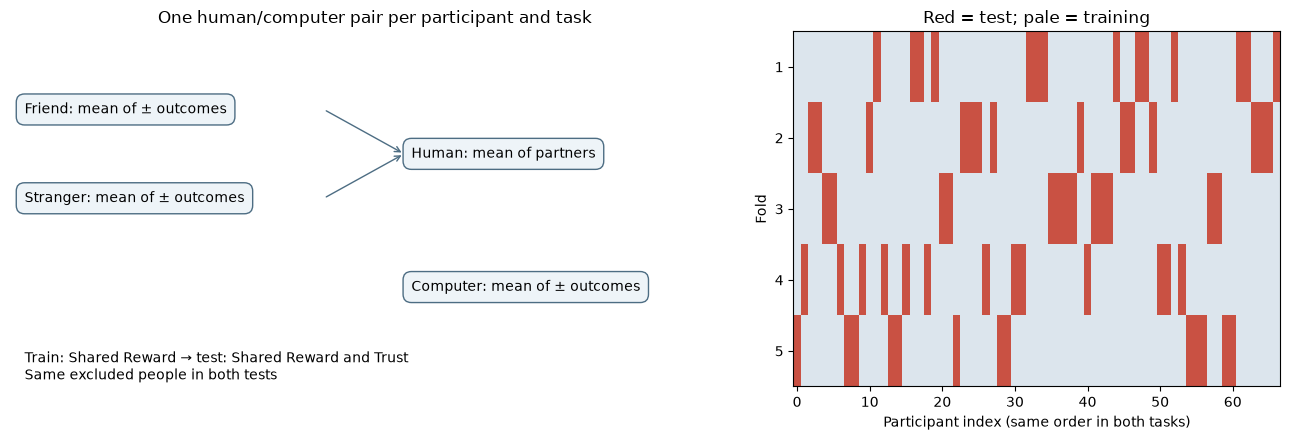

In [11]:
observed = np.load(OUTPUT_DIR / "observed_results.npz")
margins = observed["margins"]
fold_for_person = observed["fold"]
assert np.isfinite(margins).all() and set(fold_for_person) == set(range(1, 6))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
boxes = [(0.02, .78, "Friend: mean of ± outcomes"), (0.02, .53, "Stranger: mean of ± outcomes"),
         (.55, .655, "Human: mean of partners"), (.55, .28, "Computer: mean of ± outcomes")]
for x, y, text in boxes:
    ax.text(x, y, text, transform=ax.transAxes, fontsize=10, va="center",
            bbox=dict(boxstyle="round,pad=.6", fc="#eef4f8", ec="#4d6d83"))
for y in [.78, .53]:
    ax.annotate("", xy=(.54, .655), xytext=(.43, y), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="->", color="#4d6d83"))
ax.text(.02, .02, "Train: Shared Reward → test: Shared Reward and Trust\nSame excluded people in both tests", transform=ax.transAxes, fontsize=10)
ax.set_title("One human/computer pair per participant and task")
ax.set_axis_off()
allocation = fold_for_person[None, :] == np.arange(1, N_FOLDS + 1)[:, None]
axes[1].imshow(allocation, aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#dce5ed", "#c95143"]), vmin=0, vmax=1)
axes[1].set(xlabel="Participant index (same order in both tasks)", ylabel="Fold",
            yticks=range(N_FOLDS), yticklabels=range(1, N_FOLDS + 1), title="Red = test; pale = training")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "workflow_folds.png", dpi=160)
plt.show()

## 6. Read the performance and its uncertainty

**Paired ordering accuracy** is the fraction of people whose human map scores above their computer map. Chance is 50%; ties count as incorrect. This is different from classifying each individual map against a decision threshold.

A **participant bootstrap** repeatedly samples the 67 people's paired predictions with replacement. The middle 95% of bootstrap accuracies gives an interval. We use the same sampled people for both task evaluations. These intervals describe the fixed out-of-fold predictions; they do not include uncertainty from refitting training models.

,evaluation,n,paired_ordering_accuracy,ci_low,ci_high
0,SR → SR,67,0.805970,0.701493,0.895522
1,SR → Trust,67,0.880597,0.805597,0.955224


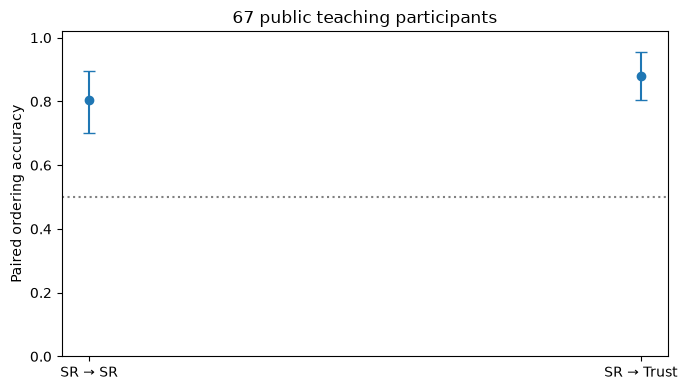

In [12]:
correct = (margins > 0).astype(float)
rng = np.random.default_rng(SEED + 1)
bootstrap_accuracies = np.zeros((2000, 2))
for repeat in range(2000):
    sampled_people = rng.integers(0, len(subjects), size=len(subjects))
    bootstrap_accuracies[repeat] = correct[sampled_people].mean(axis=0)
limits = np.quantile(bootstrap_accuracies, [0.025, 0.975], axis=0)

performance = pd.DataFrame({"evaluation": ["SR → SR", "SR → Trust"], "n": len(subjects),
    "paired_ordering_accuracy": correct.mean(axis=0), "ci_low": limits[0], "ci_high": limits[1]})
performance.to_csv(OUTPUT_DIR / "performance.csv", index=False)
display(performance)

fig, ax = plt.subplots(figsize=(7, 4))
values = performance.paired_ordering_accuracy.to_numpy()
ax.errorbar([0, 1], values, yerr=[values - limits[0], limits[1] - values], fmt="o", capsize=4)
ax.axhline(.5, color="gray", ls=":")
ax.set(xticks=[0, 1], xticklabels=performance.evaluation, ylim=(0, 1.02),
       ylabel="Paired ordering accuracy", title="67 public teaching participants")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "performance.png", dpi=150)
plt.show()

### Look beyond the average accuracy

Each dot is a person, predicted by a model trained on other people. Positive margins indicate correct human/computer ordering. Distance from zero is **not a calibrated probability**. Colors identify folds; the models' training sets overlap. The second panel connects the same person's margins across the two evaluations.

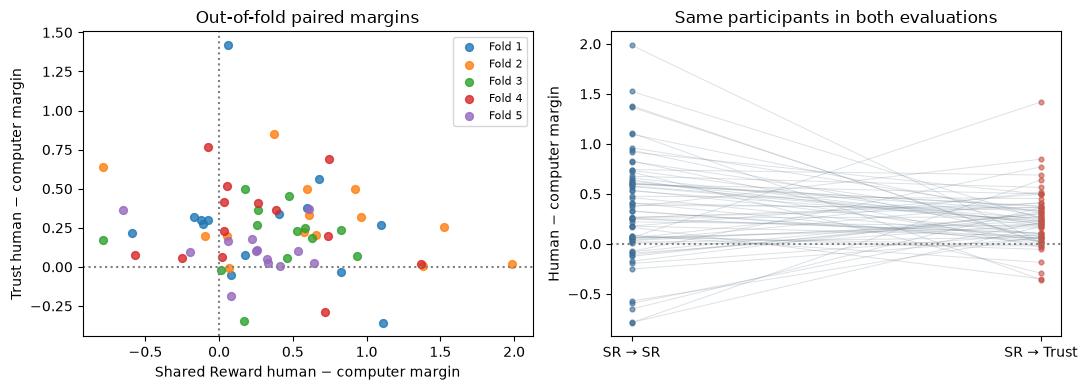

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for fold in range(1, N_FOLDS + 1):
    keep = fold_for_person == fold
    axes[0].scatter(margins[keep, 0], margins[keep, 1], s=32, alpha=.8, label=f"Fold {fold}")
axes[0].axhline(0, color="gray", ls=":")
axes[0].axvline(0, color="gray", ls=":")
axes[0].set(xlabel="Shared Reward human − computer margin", ylabel="Trust human − computer margin",
            title="Out-of-fold paired margins")
axes[0].legend(fontsize=8)
for person in range(len(subjects)):
    axes[1].plot([0, 1], margins[person], color="#708494", alpha=.24, lw=.7)
for target, color in enumerate(["#376b96", "#c95143"]):
    axes[1].scatter(np.full(len(subjects), target), margins[:, target], s=12, color=color, alpha=.6)
axes[1].axhline(0, color="gray", ls=":")
axes[1].set(xticks=[0, 1], xticklabels=["SR → SR", "SR → Trust"], ylabel="Human − computer margin",
            title="Same participants in both evaluations")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "participant_margins.png", dpi=160)
plt.show()
pd.DataFrame({"participant_index": np.arange(len(subjects)), "fold": fold_for_person,
              "sr_margin": margins[:, 0], "trust_margin": margins[:, 1]}).to_csv(OUTPUT_DIR / "paired_margins.csv", index=False)

## 7. Test a participant-blocked permutation null

A bootstrap interval and a permutation test answer different questions. Here the null asks whether **human/computer labels are exchangeable within each person**. For each of 999 permutations:

1. Randomly decide whether to swap each person's human/computer labels.
2. Apply the same swap in both tasks.
3. Refit every training fold and score the excluded people against their swapped labels.

We keep folds, maps, mask and classifier settings fixed. Shuffling a finished prediction vector would not perform this test.

### A speed step for the repeated fits

The next cell represents each fold in the complete span of its training maps. This is a change of coordinates that keeps all training directions, not a choice of high-performing voxels or a variance-selected PCA. It makes thousands of linear fits practical. Test maps are projected using **training maps only**. Before using this representation, we require the original and transformed classifiers to give matching margins and identical paired orderings.

The linear algebra here is an optional deeper topic: you can follow what goes in and out of the cell without deriving QR decomposition. The actual permutation test below remains an explicit set of loops.

In [14]:
%%script fslpython
from pathlib import Path
import json
import warnings
import numpy as np
from sklearn.model_selection import KFold
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

warnings.simplefilter("error", ConvergenceWarning)
thread_limit = threadpool_limits(limits=1)
out = Path("outputs/public")
X = np.load(out / "features.npy")
reference_margins = np.load(out / "observed_results.npz")["margins"]
settings = json.loads((out / "settings.json").read_text())
seed, n_folds, c_value = settings["seed"], settings["folds"], settings["C"]
folds = list(KFold(n_splits=n_folds, shuffle=True, random_state=seed).split(X))
fold_data = []
check_margins = np.zeros_like(reference_margins)

for train, test in folds:
    training_maps = X[train, 0].reshape(-1, X.shape[-1]).astype("float64")
    basis, _ = np.linalg.qr(training_maps.T, mode="reduced")
    small_training = training_maps @ basis
    small_targets = []
    for target_task in range(2):
        test_maps = X[test, target_task].reshape(-1, X.shape[-1])
        small_targets.append(test_maps @ basis)
    fold_data.append({"train": train, "test": test, "maps": small_training, "targets": small_targets})
    model = LinearSVC(C=c_value, dual=True, tol=1e-4, max_iter=100000, random_state=seed)
    model.fit(small_training, np.tile([1, -1], len(train)))
    for target_task in range(2):
        scores = model.decision_function(small_targets[target_task]).reshape(-1, 2)
        check_margins[test, target_task] = scores[:, 0] - scores[:, 1]

np.testing.assert_allclose(check_margins, reference_margins, atol=2e-3, rtol=2e-3)
assert np.array_equal(check_margins > 0, reference_margins > 0)
# Save numeric arrays, without Python objects or pickle, for the next cell.
arrays = {"reference_margins": reference_margins, "check_margins": check_margins}
for fold, data in enumerate(fold_data):
    for name in ["train", "test", "maps"]:
        arrays[f"{fold}_{name}"] = data[name]
    for target_task in range(2):
        arrays[f"{fold}_target_{target_task}"] = data["targets"][target_task]
np.savez(out / "permutation_inputs.npz", **arrays)
print("All paired orderings agree. Largest margin difference:", np.abs(check_margins - reference_margins).max())

All paired orderings agree. Largest margin difference: 5.329070518200751e-15


In [15]:
%%script fslpython
from pathlib import Path
import json
import time
import warnings
import numpy as np
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

warnings.simplefilter("error", ConvergenceWarning)
thread_limit = threadpool_limits(limits=1)
out = Path("outputs/public")
inputs = np.load(out / "permutation_inputs.npz")
n_people = len(inputs["reference_margins"])
settings = json.loads((out / "settings.json").read_text())
seed, n_folds, c_value = settings["seed"], settings["folds"], settings["C"]
n_permutations = settings["permutations"]
rng = np.random.default_rng(seed + 2)
all_swaps = rng.choice([-1, 1], size=(n_permutations, n_people))
null_accuracies = np.zeros((n_permutations, 2))
max_solver_iterations = 0
permutation_started = time.perf_counter()

for permutation in range(n_permutations):
    swaps = all_swaps[permutation]
    correct_count = np.zeros(2)
    for fold in range(n_folds):
        train = inputs[f"{fold}_train"]
        test = inputs[f"{fold}_test"]
        # Give both maps from a person the same decision to swap their two labels.
        labels = np.tile([1, -1], (len(train), 1)) * swaps[train, None]
        model = LinearSVC(C=c_value, dual=True, tol=1e-4, max_iter=100000, random_state=seed)
        model.fit(inputs[f"{fold}_maps"], labels.ravel())
        max_solver_iterations = max(max_solver_iterations, int(model.n_iter_))
        for target_task in range(2):
            scores = model.decision_function(inputs[f"{fold}_target_{target_task}"]).reshape(-1, 2)
            paired_margin = (scores[:, 0] - scores[:, 1]) * swaps[test]
            correct_count[target_task] += (paired_margin > 0).sum()
    null_accuracies[permutation] = correct_count / n_people
    if (permutation + 1) % 100 == 0:
        print("Completed", permutation + 1, "permutations")

elapsed = time.perf_counter() - permutation_started
np.savez_compressed(out / "permutation_null.npz", accuracies=null_accuracies,
                    seed=seed + 2, elapsed_seconds=elapsed, max_solver_iterations=max_solver_iterations)
print("Finished", n_permutations, "permutations in", round(elapsed, 1), "seconds")
print("Maximum solver iterations:", max_solver_iterations, "/ 100000")

Completed 100 permutations
Completed 200 permutations
Completed 300 permutations
Completed 400 permutations
Completed 500 permutations
Completed 600 permutations
Completed 700 permutations
Completed 800 permutations
Completed 900 permutations
Finished 999 permutations in 14.1 seconds
Maximum solver iterations: 51 / 100000


### Compare the observed accuracy with the null

The red line is the observed result; the histogram contains results from randomized labels. The uncorrected p-value is `(1 + number of null accuracies ≥ observed) / (1 + 999)`. Thus the smallest possible p-value is .001, not zero.

We also correct for the two displayed tests using the **maximum accuracy across the two tasks in each permutation**. The null mean and exceedance counts help check the randomization. The binomial interval describes uncertainty in the null exceedance probability from a finite number of permutations; it is not a confidence interval for prediction accuracy.

,evaluation,n,observed_accuracy,permutations,null_mean,exceedances,p_uncorrected,p_familywise_two_tests,null_exceedance_probability_ci95_low,null_exceedance_probability_ci95_high
0,SR → SR,67,0.805970,999,0.500276,0,0.001,0.001,0.0,0.003686
1,SR → Trust,67,0.880597,999,0.501845,0,0.001,0.001,0.0,0.003686


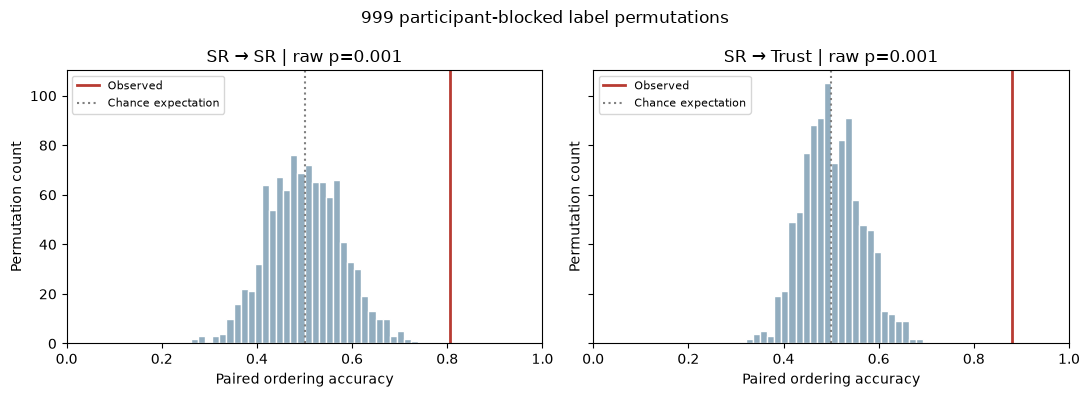

In [16]:
from scipy.stats import binomtest

randomization = np.load(OUTPUT_DIR / "permutation_null.npz")
null = randomization["accuracies"]
values = correct.mean(axis=0)
exceedances = (null >= values).sum(axis=0)
family_exceedances = (null.max(axis=1)[:, None] >= values).sum(axis=0)
mc_intervals = []
for count in exceedances:
    mc_intervals.append(binomtest(int(count), N_PERMUTATIONS).proportion_ci())

permutation_results = pd.DataFrame({"evaluation": performance.evaluation, "n": len(subjects),
    "observed_accuracy": values, "permutations": N_PERMUTATIONS, "null_mean": null.mean(axis=0),
    "exceedances": exceedances, "p_uncorrected": (exceedances + 1) / (N_PERMUTATIONS + 1),
    "p_familywise_two_tests": (family_exceedances + 1) / (N_PERMUTATIONS + 1),
    "null_exceedance_probability_ci95_low": [interval.low for interval in mc_intervals],
    "null_exceedance_probability_ci95_high": [interval.high for interval in mc_intervals]})
permutation_results.to_csv(OUTPUT_DIR / "permutation_results.csv", index=False)
display(permutation_results)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
bins = np.arange(-.5, len(subjects) + 1.5) / len(subjects)
for target, ax in enumerate(axes):
    ax.hist(null[:, target], bins=bins, color="#92adbf", edgecolor="white")
    ax.axvline(values[target], color="#b83b32", lw=2, label="Observed")
    ax.axvline(.5, color="gray", ls=":", label="Chance expectation")
    ax.set(xlim=(0, 1), xlabel="Paired ordering accuracy", ylabel="Permutation count",
           title=f"{performance.evaluation.iloc[target]} | raw p={permutation_results.p_uncorrected.iloc[target]:.3f}")
    ax.legend(fontsize=8)
fig.suptitle("999 participant-blocked label permutations")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "permutations.png", dpi=160)
plt.show()

## 8. Look at decoder coefficients and forward patterns

A **coefficient** is a voxel's weight in the decision rule. Correlated voxels can have weights whose signs and magnitudes do not match their individual association with the class. A **forward pattern** describes covariance between the training features and decoder scores, divided by score variance. Neither is a causal importance map or a voxelwise significance test.

We average maps from five overlapping training folds. Positive values align with higher human scores; negative values align with computer scores. The six axial MNI coordinates were fixed before viewing the results. Each row has its own symmetric color scale, clipped at the 99th absolute percentile **for display only**. No voxel was removed from model fitting and no significance threshold is applied.

R marks the participant's right (neurological display). The TemplateFlow anatomy is a reference underlay, not a participant image or a source of selected regions. A small teaching sample may produce patterns different from the larger research sample; do not change analysis choices to make them look stronger.

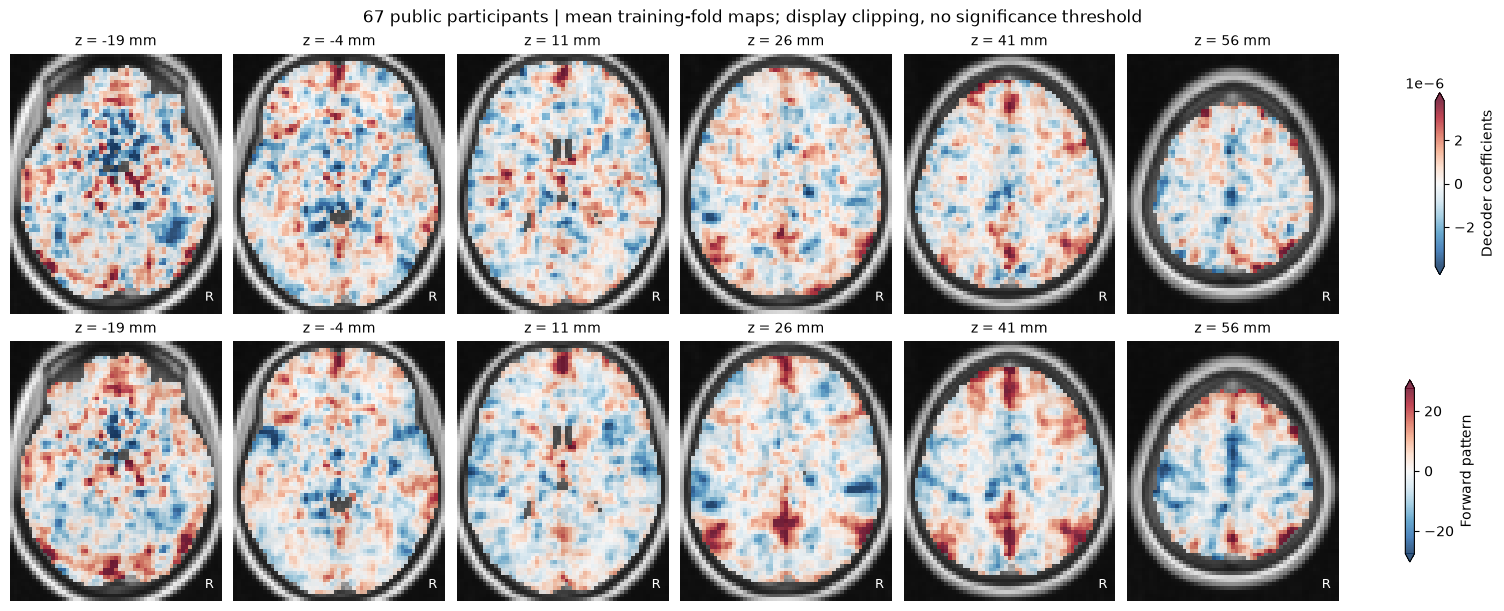

In [17]:
weights = observed["weights"].mean(axis=0)
forward_pattern = observed["forward_patterns"].mean(axis=0)
background = nib.as_closest_canonical(anatomy).get_fdata()
canonical_mask = nib.as_closest_canonical(nib.Nifti1Image(mask_values, reference.affine)).get_fdata() > 0
z_coordinates = [-20, -5, 10, 25, 40, 55]

fig, axes = plt.subplots(2, 6, figsize=(15, 6), layout="constrained")
for row, (values, title) in enumerate(zip([weights, forward_pattern], ["Decoder coefficients", "Forward pattern"])):
    volume = np.zeros(reference.shape, dtype="float32")
    volume[mask] = values
    image = nib.as_closest_canonical(nib.Nifti1Image(volume, reference.affine))
    data = image.get_fdata()
    color_limit = float(np.quantile(np.abs(values), .99))
    for column, z in enumerate(z_coordinates):
        voxel = nib.affines.apply_affine(np.linalg.inv(image.affine), [0, 0, z])
        k = int(round(voxel[2]))
        ax = axes[row, column]
        ax.imshow(background[:, :, k].T, origin="lower", cmap="gray", vmin=0, vmax=np.quantile(background, .99))
        plane = np.ma.masked_where(~canonical_mask[:, :, k].T, data[:, :, k].T)
        view = ax.imshow(plane, origin="lower", cmap="RdBu_r", vmin=-color_limit, vmax=color_limit, alpha=.8)
        ax.text(.92, .05, "R", color="white", transform=ax.transAxes, fontsize=9)
        actual_z = nib.affines.apply_affine(image.affine, [0, 0, k])[2]
        ax.set_title(f"z = {actual_z:.0f} mm", fontsize=10)
        ax.set_axis_off()
    fig.colorbar(view, ax=axes[row].tolist(), shrink=.7, label=title, extend="both")
fig.suptitle("67 public participants | mean training-fold maps; display clipping, no significance threshold")
fig.savefig(OUTPUT_DIR / "patterns.png", dpi=180)
plt.show()

## 9. What can we conclude?

Cross-task prediction demonstrates generalization across these particular task contrasts in excluded tutorial participants. It does not establish an abstract or uniquely social representation. Relational context, task-related deactivation and other shared task features can contribute. Permutation evidence depends on the stated exchangeability assumption. Bootstrap intervals omit uncertainty from training-model refits, and the overlapping fold maps are not independent replications.

**Discuss:** Why would randomly splitting individual maps leak participant information? What does averaging valence remove, and what might remain? Why do coefficients and forward patterns have different interpretations? What independent dataset would provide an informative next test?

The tutorial's results must not feed back into selection of the parent paper's frozen signatures or access to its reserved cohort.

## 10. Record the environment and results

Record both Python environments: the default Neurodesk kernel for data handling and plotting, and the versioned FSL Python for classifier fitting. This records what actually ran without asking the learner to install or configure software. First-run module retrieval and data downloads take longer than cached execution.

In [18]:
import importlib.metadata

base_versions = {}
for package in ["numpy", "pandas", "nibabel", "matplotlib", "scipy", "watermark"]:
    base_versions[package] = importlib.metadata.version(package)

record = {"mode": "public", "python": platform.python_version(), "base_packages": base_versions,
    "neurodesktop_image": os.environ.get("JUPYTER_IMAGE", os.environ.get("NEURODESKTOP_VERSION", "unknown")),
    "module": "fsl/6.0.7.22",
    "fsl_python": json.loads((OUTPUT_DIR / "fsl_python_environment.json").read_text()),
    "n": len(subjects), "input_map_files": len(manifest), "masked_voxels": int(mask.sum()),
    "permutations": N_PERMUTATIONS, "permutation_seconds": float(randomization["elapsed_seconds"]),
    "max_permutation_solver_iterations": int(randomization["max_solver_iterations"]),
    "paired_accuracies": correct.mean(axis=0).tolist(),
    "permutation_p_uncorrected": permutation_results.p_uncorrected.tolist(),
    "permutation_p_familywise": permutation_results.p_familywise_two_tests.tolist(),
    "elapsed_seconds": time.perf_counter() - started, "real_public_data_used": True,
    "package_installation_required": False, "custom_kernel_required": False}
(OUTPUT_DIR / "execution_summary.json").write_text(json.dumps(record, indent=2) + "\n")
print(json.dumps(record, indent=2))
print("Completed: public teaching dataset")

{
  "mode": "public",
  "python": "3.13.15",
  "base_packages": {
    "numpy": "2.5.3",
    "pandas": "3.0.6",
    "nibabel": "5.4.2",
    "matplotlib": "3.11.2",
    "scipy": "1.18.1",
    "watermark": "2.6.0"
  },
  "neurodesktop_image": "ghcr.io/neurodesk/neurodesktop:2026-10-07",
  "module": "fsl/6.0.7.22",
  "fsl_python": {
    "python": "3.12.13",
    "packages": {
      "numpy": "2.1.3",
      "scipy": "1.17.1",
      "scikit-learn": "1.5.2",
      "threadpoolctl": "3.6.0"
    }
  },
  "n": 67,
  "input_map_files": 804,
  "masked_voxels": 84479,
  "permutations": 999,
  "permutation_seconds": 14.133866179967299,
  "max_permutation_solver_iterations": 51,
  "paired_accuracies": [
    0.8059701492537313,
    0.8805970149253731
  ],
  "permutation_p_uncorrected": [
    0.001,
    0.001
  ],
  "permutation_p_familywise": [
    0.001,
    0.001
  ],
  "elapsed_seconds": 42.928558302111924,
  "real_public_data_used": true,
  "package_installation_required": false,
  "custom_kernel_req

In [19]:
%load_ext watermark
%watermark
%watermark --iversions

Last updated: 2026-10-28T14:42:55.836240+00:00

Python implementation: CPython
Python version       : 3.13.15
IPython version      : 9.17.1

Compiler    : GCC 15.3.0
OS          : Linux
Release     : 7.0.0-34-generic
Machine     : x86_64
Processor   : x86_64
CPU cores   : 32
Architecture: 64bit

IPython   : 9.17.1
json      : 2.0.9
matplotlib: 3.11.2
nibabel   : 5.4.2
numpy     : 2.5.3
pandas    : 3.0.6
platform  : 1.0.8
scipy     : 1.18.1



## Citations and resources

- Source: [OpenNeuro ds005123 v1.0.0](https://doi.org/10.18112/openneuro.ds005123.v1.0.0) and its [data paper](https://pubmed.ncbi.nlm.nih.gov/39252767/).
- Teaching maps: [Zenodo 10.5281/zenodo.23718599](https://doi.org/10.5281/zenodo.23718599).
- [Neurodesk citation guidance](https://neurodesk.org/overview/how-to-cite-us/) and [using versioned modules](https://neurodesk.org/edu/tutorials/about_neurodesk/accessing_neurodesk_tools.html).
- [Scikit-learn](https://jmlr.org/papers/v12/pedregosa11a.html), [NiBabel](https://nipy.org/nibabel/) and [FSL](https://fsl.fmrib.ox.ac.uk/fsl/docs/).
- Forward patterns: [Haufe et al., 2014](https://doi.org/10.1016/j.neuroimage.2013.10.067).
- Reference images: [TemplateFlow MNI152NLin6Asym](https://github.com/templateflow/tpl-MNI152NLin6Asym). Upstream terms apply to downloaded references and anatomical underlays.
- [NeurodeskEDU contribution guide](https://neurodesk.org/edu/contribute/examples/), [README](https://github.com/neurodesk/neurodeskedu/blob/main/README.md) and [template](https://github.com/neurodesk/neurodeskedu/blob/main/books/examples/template.ipynb).